# Solving the 1D heat equation: PINN, spline PIKAN, and finite differences

This notebook implements the comparison proposed in `PIKAN_Heat_Equation_Academic_Project_Proposal.pdf` and adds a classical Crank–Nicolson finite difference solver. Both networks learn the same initial–boundary value problem using physics losses and **no interior temperature labels**. The exact solution is reserved for validation and the final evaluation.

**Study scope:** This is a controlled implementation exercise and architecture comparison for one smooth PDE instance, not a practical speed benchmark for general heat solvers. Because this particular case has a closed-form solution, direct formula evaluation is also benchmarked below.

Run top to bottom in the `ml` environment. The default experiment uses CPU so the timing comparison uses the same hardware for every run. For a faster draft, reduce `STEPS` and/or `SEEDS` below; rerun all cells before interpreting the conclusions.

**Problem:** $T_t=\alpha T_{xx}$ on $(x,t)\in[0,1]^2$, $\alpha=0.1$, $T(x,0)=\sin(\pi x)$, $T(0,t)=T(1,t)=0$. The exact solution is $T(x,t)=e^{-\alpha\pi^2t}\sin(\pi x)$.

In [1]:
import math
import time
from dataclasses import dataclass

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch import nn

torch.set_num_threads(min(4, torch.get_num_threads()))
DEVICE = torch.device("cpu")
DTYPE = torch.float32
ALPHA = 0.1
STEPS = 400
SEEDS = (0, 1, 2, 3, 4)
N_INTERIOR, N_INITIAL, N_BOUNDARY = 96, 48, 48
LR = 3e-3
WEIGHTS = {"physics": 1.0, "initial": 10.0, "boundary": 10.0}
print(f"PyTorch {torch.__version__}; device={DEVICE}; steps={STEPS}; seeds={SEEDS}")

PyTorch 2.13.0+cu130; device=cpu; steps=400; seeds=(0, 1, 2, 3, 4)


## 1. Exact solution and collocation points

Each seed generates one fixed collection of uniformly sampled interior, initial, and boundary points. The MLP and KAN for that seed receive **identical points**, weights, Adam settings, and update counts. Fixed points make this small comparison easy to reproduce; they also mean the result measures fit to one collocation design per seed.

In [2]:
def exact_temperature(coords):
    x, t = coords[:, :1], coords[:, 1:2]
    return torch.exp(-ALPHA * math.pi**2 * t) * torch.sin(math.pi * x)


def sample_points(seed):
    rng = torch.Generator(device="cpu").manual_seed(seed)
    interior = torch.rand(N_INTERIOR, 2, generator=rng, dtype=DTYPE)
    initial = torch.cat((torch.rand(N_INITIAL, 1, generator=rng, dtype=DTYPE),
                         torch.zeros(N_INITIAL, 1, dtype=DTYPE)), dim=1)
    boundary = torch.rand(N_BOUNDARY, 2, generator=rng, dtype=DTYPE)
    boundary[:, 0] = torch.arange(N_BOUNDARY) % 2
    return interior.to(DEVICE), initial.to(DEVICE), boundary.to(DEVICE)


def pde_residual(model, coords, create_graph=True):
    coords = coords.detach().clone().requires_grad_(True)
    value = model(coords)
    first = torch.autograd.grad(value, coords, torch.ones_like(value), create_graph=True)[0]
    second_x = torch.autograd.grad(first[:, :1], coords,
                                   torch.ones_like(first[:, :1]),
                                   create_graph=create_graph)[0][:, :1]
    return first[:, 1:2] - ALPHA * second_x


class ExactModel(nn.Module):
    def forward(self, coords):
        return exact_temperature(coords)


probe = torch.rand(64, 2, generator=torch.Generator().manual_seed(2026))
exact_residual = pde_residual(ExactModel(), probe, create_graph=False)
assert exact_residual.abs().max() < 2e-6
print("Exact-solution PDE residual, max absolute:", f"{exact_residual.abs().max().item():.2e}")

Exact-solution PDE residual, max absolute: 1.19e-07


## 2. Architectures

The PINN is a two hidden layer tanh MLP. Each PIKAN edge has a trainable scalar base branch plus a trainable **cubic B-spline** expansion; node outputs sum their incoming edge functions. The spline knots are fixed and shared across edges, and hidden nodes use tanh to keep their inputs in the spline range. `grid_size` is the number of spline centers per edge. This is a **KAN-style variant** with genuine learned univariate edge functions. The added hidden tanh and fixed grid mean its results should not be generalized to every KAN implementation.

The MLP width is chosen to nearly match the trainable parameter count of the 8-center PIKAN. The 12-center KAN is an additional grid-size sensitivity check and therefore has more parameters.

In [3]:
def cubic_spline_basis(z):
    # Centered cardinal cubic B-spline, support [-2, 2], C2 continuous.
    a = z.abs()
    inner = 2.0 / 3.0 - a.square() + 0.5 * a.pow(3)
    outer = (2.0 - a).clamp_min(0).pow(3) / 6.0
    return torch.where(a < 1.0, inner, outer)


class SplineKANLayer(nn.Module):
    def __init__(self, in_features, out_features, grid_size=8):
        super().__init__()
        centers = torch.linspace(-1.25, 1.25, grid_size)
        self.register_buffer("centers", centers)
        self.spacing = float(centers[1] - centers[0])
        self.base = nn.Linear(in_features, out_features)
        self.spline = nn.Parameter(torch.empty(out_features, in_features, grid_size))
        nn.init.normal_(self.spline, std=0.02)

    def forward(self, inputs):
        z = (inputs.unsqueeze(-1) - self.centers) / self.spacing
        basis = cubic_spline_basis(z)
        return self.base(torch.nn.functional.silu(inputs)) + torch.einsum("nig,oig->no", basis, self.spline)


class PIKAN(nn.Module):
    def __init__(self, grid_size=8):
        super().__init__()
        self.layers = nn.ModuleList([
            SplineKANLayer(2, 6, grid_size),
            SplineKANLayer(6, 6, grid_size),
            SplineKANLayer(6, 1, grid_size),
        ])

    def forward(self, coords):
        values = 2 * coords - 1  # physical [0, 1] coordinates to spline input range
        for layer in self.layers[:-1]:
            values = torch.tanh(layer(values))
        return self.layers[-1](values)


class PINN(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(2, 20), nn.Tanh(),
                                 nn.Linear(20, 20), nn.Tanh(), nn.Linear(20, 1))

    def forward(self, coords):
        return self.net(2 * coords - 1)


def parameter_count(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


for name, model in [("PINN", PINN()), ("PIKAN-8", PIKAN(8)), ("PIKAN-12", PIKAN(12))]:
    print(f"{name}: {parameter_count(model)} trainable parameters")

PINN: 501 trainable parameters
PIKAN-8: 499 trainable parameters
PIKAN-12: 715 trainable parameters


### Derivative check

The PDE loss depends on second spatial derivatives. Check the spline branch's autograd curvature against a finite difference at a point away from knot boundaries, then check that both full models permit second derivatives with respect to physical coordinates.

In [4]:
z = torch.tensor([0.37], dtype=torch.float64, requires_grad=True)
first = torch.autograd.grad(cubic_spline_basis(z), z, create_graph=True)[0]
second = torch.autograd.grad(first, z)[0].item()
h = 1e-3
finite_difference = ((cubic_spline_basis(z.detach() + h)
                      - 2 * cubic_spline_basis(z.detach())
                      + cubic_spline_basis(z.detach() - h)) / h**2).item()
assert abs(second - finite_difference) < 2e-3
for model in (PINN(), PIKAN(8)):
    residual = pde_residual(model, probe[:8], create_graph=False)
    assert torch.isfinite(residual).all()
print(f"Spline B''(0.37): autograd={second:.6f}, finite difference={finite_difference:.6f}; full-model derivatives finite")

Spline B''(0.37): autograd=-0.890000, finite difference=-0.890000; full-model derivatives finite


## 3. Shared physics-informed training

For both networks, $\mathcal L=\lambda_p\,\mathrm{MSE}(T_t-\alpha T_{xx})+\lambda_i\,\mathrm{MSE}(T(x,0)-\sin\pi x)+\lambda_b\,\mathrm{MSE}(T(0,t),T(1,t))$. The weights above are identical for all runs. Each run uses a fresh random initialization and the same seed's collocation points. Wall time includes model setup and optimizer steps. We first compare 400 updates per model, then train a second PINN for approximately the time spent on that seed's 400-step KAN run.

In [5]:
def loss_terms(model, interior, initial, boundary):
    residual = pde_residual(model, interior, create_graph=True)
    physics = residual.square().mean()
    initial_loss = (model(initial) - torch.sin(math.pi * initial[:, :1])).square().mean()
    boundary_loss = model(boundary).square().mean()
    return physics, initial_loss, boundary_loss


def train_model(name, seed, time_budget_seconds=None):
    start = time.perf_counter()
    torch.manual_seed(10_000 + seed)
    model = PINN() if name.startswith("PINN") else PIKAN(int(name.split("-")[1]))
    model = model.to(DEVICE)
    interior, initial, boundary = sample_points(seed)
    optimizer = torch.optim.Adam(model.parameters(), lr=LR)
    history = []
    step = 0
    while True:
        step += 1
        optimizer.zero_grad(set_to_none=True)
        lp, li, lb = loss_terms(model, interior, initial, boundary)
        total = WEIGHTS["physics"] * lp + WEIGHTS["initial"] * li + WEIGHTS["boundary"] * lb
        if not torch.isfinite(total):
            raise FloatingPointError(f"Non-finite loss for {name}, seed {seed}, step {step}")
        total.backward()
        optimizer.step()
        elapsed = time.perf_counter() - start
        stop = elapsed >= time_budget_seconds if time_budget_seconds is not None else step >= STEPS
        if step == 1 or step % 20 == 0 or stop:
            history.append({"model": name, "seed": seed, "step": step,
                            "total": total.item(), "physics": lp.item(),
                            "initial": li.item(), "boundary": lb.item()})
        if stop:
            break
    return model, time.perf_counter() - start, history


RUNS = [(name, seed) for seed in SEEDS for name in ("PINN", "PIKAN-8")] + [("PIKAN-12", SEEDS[0])]
models, train_times, histories = {}, {}, []
for name, seed in RUNS:
    model, seconds, history = train_model(name, seed)
    models[(name, seed)] = model
    train_times[(name, seed)] = seconds
    histories.extend(history)
    print(f"{name:9s} seed={seed}: {seconds:.1f}s, final loss={history[-1]['total']:.3e}")
for seed in SEEDS:
    key = ("PINN-time", seed)
    model, seconds, history = train_model(*key, time_budget_seconds=train_times[("PIKAN-8", seed)])
    models[key] = model
    train_times[key] = seconds
    histories.extend(history)
    RUNS.append(key)
    print(f"{key[0]:9s} seed={seed}: {seconds:.1f}s, {history[-1]['step']} updates, "
          f"final loss={history[-1]['total']:.3e}")
history_df = pd.DataFrame(histories)

PINN      seed=0: 0.4s, final loss=2.168e-03
PIKAN-8   seed=0: 3.5s, final loss=5.490e-04
PINN      seed=1: 0.5s, final loss=3.719e-03
PIKAN-8   seed=1: 3.4s, final loss=2.752e-04
PINN      seed=2: 0.5s, final loss=2.010e-02
PIKAN-8   seed=2: 3.3s, final loss=4.743e-04
PINN      seed=3: 0.4s, final loss=3.793e-03
PIKAN-8   seed=3: 3.3s, final loss=7.207e-04
PINN      seed=4: 0.4s, final loss=4.296e-03
PIKAN-8   seed=4: 3.2s, final loss=3.913e-04
PIKAN-12  seed=0: 3.8s, final loss=1.419e-04
PINN-time seed=0: 3.5s, 3165 updates, final loss=1.567e-04
PINN-time seed=1: 3.4s, 3138 updates, final loss=2.211e-03
PINN-time seed=2: 3.3s, 3178 updates, final loss=1.037e-04
PINN-time seed=3: 3.3s, 3085 updates, final loss=9.600e-05
PINN-time seed=4: 3.2s, 2856 updates, final loss=4.380e-05


## 4. Held-out evaluation

Accuracy is measured on a 101 × 101 grid. Physics residual and boundary error use separate deterministic test points, distinct from the training points. Relative $L_2$ divides by the exact solution's $L_2$ norm. Inference latency is the mean time for a 1024-point batch on CPU, after warm-up; it excludes derivative calculations.

In [6]:
axis = torch.linspace(0, 1, 101, device=DEVICE)
xx, tt = torch.meshgrid(axis, axis, indexing="ij")
test_coords = torch.stack((xx.reshape(-1), tt.reshape(-1)), dim=1)
truth = exact_temperature(test_coords).detach()
rng = torch.Generator().manual_seed(99_991)
residual_coords = torch.rand(512, 2, generator=rng, dtype=DTYPE).to(DEVICE)
boundary_times = torch.linspace(0, 1, 101, device=DEVICE).unsqueeze(1)
test_boundary = torch.cat((torch.cat((torch.zeros_like(boundary_times), boundary_times), 1),
                           torch.cat((torch.ones_like(boundary_times), boundary_times), 1)), 0)
latency_coords = test_coords[:1024]


def evaluate(model, name, seed):
    model.eval()
    with torch.no_grad():
        prediction = model(test_coords)
        rmse = (prediction - truth).square().mean().sqrt().item()
        relative_l2 = ((prediction - truth).norm() / truth.norm()).item()
        boundary_rmse = model(test_boundary).square().mean().sqrt().item()
        initial_coords = torch.stack((axis, torch.zeros_like(axis)), dim=1)
        initial_rmse = (model(initial_coords) - exact_temperature(initial_coords)).square().mean().sqrt().item()
        for _ in range(5):
            model(latency_coords)
        start = time.perf_counter()
        for _ in range(30):
            model(latency_coords)
        latency_ms = (time.perf_counter() - start) * 1000 / 30
    residual_rmse = pde_residual(model, residual_coords, create_graph=False).square().mean().sqrt().item()
    return {"model": name, "seed": seed, "parameters": parameter_count(model),
            "RMSE": rmse, "relative_L2": relative_l2, "PDE_residual_RMSE": residual_rmse,
            "initial_RMSE": initial_rmse, "boundary_RMSE": boundary_rmse,
            "train_seconds": train_times[(name, seed)], "inference_ms_per_1024": latency_ms}


results = pd.DataFrame([evaluate(models[key], *key) for key in RUNS])
display(results.style.format({c: "{:.4g}" for c in results.select_dtypes("number").columns if c != "seed" and c != "parameters"}))

,model,seed,parameters,RMSE,relative_L2,PDE_residual_RMSE,initial_RMSE,boundary_RMSE,train_seconds,inference_ms_per_1024
0,PINN,0,501,0.01024,0.02201,0.03924,0.008465,0.006969,0.4341,0.1025
1,PIKAN-8,0,499,0.004499,0.009666,0.06357,0.002793,0.003821,3.522,0.5977
2,PINN,1,501,0.007106,0.01527,0.06911,0.00744,0.007106,0.4505,0.08421
3,PIKAN-8,1,499,0.004123,0.008859,0.06014,0.002816,0.002005,3.409,0.601
4,PINN,2,501,0.01621,0.03483,0.1598,0.01455,0.01725,0.4611,0.07398
5,PIKAN-8,2,499,0.00618,0.01328,0.0851,0.005705,0.003942,3.322,0.5994
6,PINN,3,501,0.006333,0.01361,0.05226,0.004777,0.005321,0.429,0.07541
7,PIKAN-8,3,499,0.003399,0.007303,0.05057,0.003603,0.003272,3.292,0.5955
8,PINN,4,501,0.005261,0.0113,0.05716,0.006916,0.004336,0.4175,0.07452
9,PIKAN-8,4,499,0.005148,0.01106,0.08257,0.003499,0.003356,3.233,0.5919


## 5. Classical numerical baseline

Crank–Nicolson uses centered second differences in space and the trapezoidal rule in time. Each step solves a tridiagonal sparse system; the factorization is reused. For the direct comparison, 100 space and 100 time intervals produce the **same 101 × 101 grid** used for neural evaluation. Its solve time includes matrix construction, factorization, and all time steps. A resolution sweep checks numerical convergence rather than relying on one arbitrary grid.

The finite difference solver computes this one initial–boundary value problem. Neural training creates a reusable continuous surrogate, so the cost comparison below is specifically for producing one full solution field, not for repeated solves with varied conditions or arbitrary coordinate queries.

In [7]:
from scipy.sparse import diags, eye
from scipy.sparse.linalg import splu


def crank_nicolson(nx=100, nt=100):
    x = np.linspace(0.0, 1.0, nx + 1)
    t = np.linspace(0.0, 1.0, nt + 1)
    dx, dt = 1.0 / nx, 1.0 / nt
    ratio = ALPHA * dt / dx**2
    interior_count = nx - 1
    laplacian = diags((np.ones(interior_count - 1),
                       -2 * np.ones(interior_count),
                       np.ones(interior_count - 1)), (-1, 0, 1), format="csc")
    identity = eye(interior_count, format="csc")
    left = (identity - 0.5 * ratio * laplacian).tocsc()
    right = (identity + 0.5 * ratio * laplacian).tocsc()
    solve = splu(left).solve
    field = np.zeros((nx + 1, nt + 1), dtype=np.float64)
    field[:, 0] = np.sin(np.pi * x)
    state = field[1:-1, 0].copy()
    for step in range(1, nt + 1):
        state = solve(right @ state)
        field[1:-1, step] = state
    return x, t, field


def exact_on_grid(x, t):
    return np.sin(np.pi * x[:, None]) * np.exp(-ALPHA * np.pi**2 * t[None, :])


def time_call(fn, repeats=20):
    fn()  # warm-up outside timed repetitions
    durations = []
    for _ in range(repeats):
        start = time.perf_counter()
        fn()
        durations.append(time.perf_counter() - start)
    return float(np.median(durations))


cn_x, cn_t, cn_field = crank_nicolson(100, 100)
assert np.max(np.abs(cn_field[:, 0] - np.sin(np.pi * cn_x))) < 1e-14
assert np.max(np.abs(cn_field[[0, -1], 1:])) == 0
cn_exact = exact_on_grid(cn_x, cn_t)
cn_error = cn_field - cn_exact
cn_rmse = float(np.sqrt(np.mean(cn_error**2)))
cn_relative_l2 = float(np.linalg.norm(cn_error) / np.linalg.norm(cn_exact))
cn_full_seconds = time_call(lambda: crank_nicolson(100, 100))

resolution_rows = []
for intervals in (25, 50, 100, 200):
    x, t, field = crank_nicolson(intervals, intervals)
    reference = exact_on_grid(x, t)
    resolution_rows.append({"intervals": intervals, "dx": 1 / intervals,
                            "RMSE": float(np.sqrt(np.mean((field - reference)**2))),
                            "relative_L2": float(np.linalg.norm(field - reference) / np.linalg.norm(reference)),
                            "solve_ms": 1000 * time_call(lambda n=intervals: crank_nicolson(n, n), repeats=12)})
resolution_df = pd.DataFrame(resolution_rows)

def full_grid_inference(model):
    with torch.no_grad():
        return model(test_coords)

neural_grid_seconds = {key: time_call(lambda m=model: full_grid_inference(m), repeats=20)
                       for key, model in models.items()}
results["full_grid_inference_ms"] = [1000 * neural_grid_seconds[key] for key in RUNS]
results["one_field_seconds"] = [train_times[key] + neural_grid_seconds[key] for key in RUNS]
comparison = pd.concat([
    results[["model", "seed", "RMSE", "relative_L2", "one_field_seconds"]],
    pd.DataFrame([{"model": "Crank–Nicolson 100×100", "seed": np.nan,
                   "RMSE": cn_rmse, "relative_L2": cn_relative_l2,
                   "one_field_seconds": cn_full_seconds}])
], ignore_index=True)
display(comparison.style.format({"RMSE": "{:.5g}", "relative_L2": "{:.5g}",
                                 "one_field_seconds": "{:.5g}"}))
display(resolution_df.style.format({"dx": "{:.4g}", "RMSE": "{:.5g}",
                                     "relative_L2": "{:.5g}", "solve_ms": "{:.3f}"}))

,model,seed,RMSE,relative_L2,one_field_seconds
0,PINN,0.000000,0.010244,0.02201,0.4344
1,PIKAN-8,0.000000,0.0044985,0.0096655,3.5271
2,PINN,1.000000,0.007106,0.015268,0.45079
3,PIKAN-8,1.000000,0.0041233,0.0088593,3.4147
4,PINN,2.000000,0.016212,0.034832,0.46137
5,PIKAN-8,2.000000,0.0061802,0.013279,3.3279
6,PINN,3.000000,0.0063328,0.013607,0.42923
7,PIKAN-8,3.000000,0.0033989,0.0073029,3.2969
8,PINN,4.000000,0.005261,0.011304,0.41779
9,PIKAN-8,4.000000,0.0051483,0.011062,3.2379


,intervals,dx,RMSE,relative_L2,solve_ms
0,25,0.04,0.00023212,0.00050379,0.542
1,50,0.02,5.8673e-05,0.00012649,0.797
2,100,0.01,1.4751e-05,3.1695e-05,1.406
3,200,0.005,3.6984e-06,7.9327e-06,6.168


### Repeated-query speed after training

For a fixed problem, the neural network can be evaluated again without retraining. Two reuse cases matter: (1) request the same 101 × 101 field again, or (2) request 1024 new random coordinates. We compare these with both a fresh numerical solve and a **cached** Crank–Nicolson field. Random coordinates from the cached field use bilinear interpolation. Timings are median CPU wall times after warm-up and exclude plotting. The cached-field comparison is the relevant one when the PDE inputs do not change.

Cached Crank–Nicolson: 1024 random queries, 0.0969 ms; relative L2 interpolation error 6.326e-05.
Cached 101×101 field copy: 0.001959 ms; fresh numerical solve: 1.431 ms.
Known exact formula: 101×101 field in 0.04018 ms; 1024 random queries in 0.01595 ms (zero modeling error).


,relative_L2_mean,query_1024_ms_mean
model,,
PIKAN-12,0.010333,0.674442
PIKAN-8,0.010360,0.657224
PINN,0.019906,0.095461
PINN-time,0.004362,0.081510


,full_grid_inference_ms_mean,full_grid_inference_ms_std
model,,
PIKAN-12,7.158459,NaN
PIKAN-8,5.438723,0.060865
PINN,0.270959,0.008524
PINN-time,0.243373,0.003772


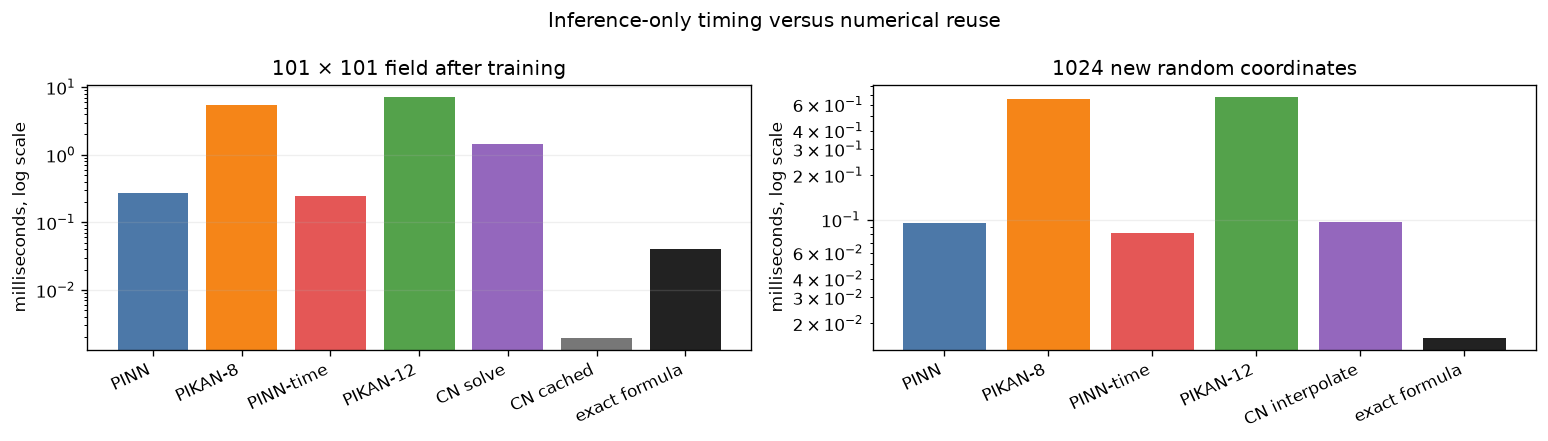

In [8]:
from scipy.interpolate import RegularGridInterpolator

query_coords = torch.rand(1024, 2, generator=torch.Generator().manual_seed(29_029), dtype=DTYPE)
query_numpy = query_coords.numpy().astype(np.float64)
query_truth = exact_temperature(query_coords).detach().numpy().ravel()
cn_interpolator = RegularGridInterpolator((cn_x, cn_t), cn_field, method="linear")
cn_query_values = cn_interpolator(query_numpy)
cn_query_error = float(np.linalg.norm(cn_query_values - query_truth) / np.linalg.norm(query_truth))
cn_query_ms = 1000 * time_call(lambda: cn_interpolator(query_numpy), repeats=50)
cn_cached_field_ms = 1000 * time_call(lambda: cn_field.copy(), repeats=50)
exact_grid_ms = 1000 * time_call(lambda: exact_temperature(test_coords), repeats=50)
exact_query_ms = 1000 * time_call(lambda: exact_temperature(query_coords), repeats=50)

query_rows = []
for key in RUNS:
    model = models[key]
    with torch.no_grad():
        values = model(query_coords).numpy().ravel()
        latency = 1000 * time_call(lambda m=model: m(query_coords), repeats=50)
    query_rows.append({"model": key[0], "seed": key[1], "relative_L2": float(np.linalg.norm(values - query_truth) / np.linalg.norm(query_truth)),
                       "query_1024_ms": latency})
query_results = pd.DataFrame(query_rows)
query_summary = query_results.groupby("model").agg(relative_L2_mean=("relative_L2", "mean"),
                                                    query_1024_ms_mean=("query_1024_ms", "mean"))
display(query_summary)
print(f"Cached Crank–Nicolson: 1024 random queries, {cn_query_ms:.4g} ms; "
      f"relative L2 interpolation error {cn_query_error:.4g}.")
print(f"Cached 101×101 field copy: {cn_cached_field_ms:.4g} ms; "
      f"fresh numerical solve: {1000 * cn_full_seconds:.4g} ms.")
print(f"Known exact formula: 101×101 field in {exact_grid_ms:.4g} ms; "
      f"1024 random queries in {exact_query_ms:.4g} ms (zero modeling error).")
display(results.groupby("model").full_grid_inference_ms.agg(["mean", "std"]).rename(
    columns={"mean": "full_grid_inference_ms_mean", "std": "full_grid_inference_ms_std"}))

fig, axes = plt.subplots(1, 2, figsize=(13, 3.7))
methods = ("PINN", "PIKAN-8", "PINN-time", "PIKAN-12")
field_ms = [results.loc[results.model == name, "full_grid_inference_ms"].mean() for name in methods]
axes[0].bar(range(7), field_ms + [1000 * cn_full_seconds, cn_cached_field_ms, exact_grid_ms],
            color=["#4c78a8", "#f58518", "#e45756", "#54a24b", "#9467bd", "#777777", "#222222"])
axes[0].set_xticks(range(7), [*methods, "CN solve", "CN cached", "exact formula"], rotation=25, ha="right")
axes[0].set(ylabel="milliseconds, log scale", title="101 × 101 field after training")
axes[0].set_yscale("log")
query_ms = [query_summary.loc[name, "query_1024_ms_mean"] for name in methods]
axes[1].bar(range(6), query_ms + [cn_query_ms, exact_query_ms],
            color=["#4c78a8", "#f58518", "#e45756", "#54a24b", "#9467bd", "#222222"])
axes[1].set_xticks(range(6), [*methods, "CN interpolate", "exact formula"], rotation=25, ha="right")
axes[1].set(ylabel="milliseconds, log scale", title="1024 new random coordinates")
axes[1].set_yscale("log")
for ax in axes:
    ax.grid(axis="y", alpha=.2)
fig.suptitle("Inference-only timing versus numerical reuse")
plt.tight_layout()
plt.show()

## 6. Graphs

The first plot shows convergence of the weighted training objective for equal-step runs. The line and heatmap plots use seed 0 for a direct visual comparison. The metric plots show all five matched seeds for equal-step and equal-time neural comparisons and the single exploratory 12-center run. The final plot compares one-field accuracy and cost with Crank–Nicolson and shows its resolution convergence.

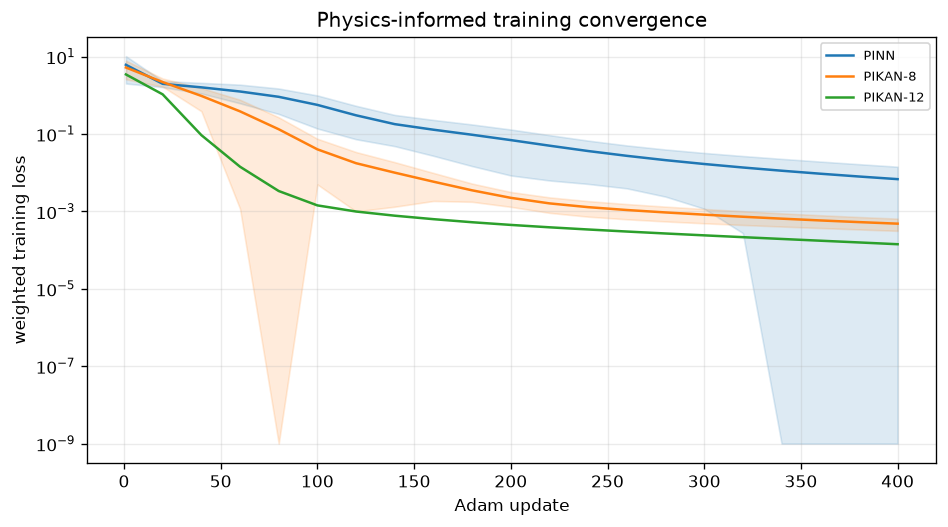

In [9]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for name, group in history_df[history_df.model != "PINN-time"].groupby("model", sort=False):
    by_step = group.groupby("step").total.agg(["mean", "std"])
    line, = ax.semilogy(by_step.index, by_step["mean"], label=name)
    if by_step["std"].notna().any():
        lower = np.maximum(by_step["mean"] - by_step["std"], 1e-9)
        upper = by_step["mean"] + by_step["std"]
        ax.fill_between(by_step.index, lower, upper, color=line.get_color(), alpha=.15)
ax.set(xlabel="Adam update", ylabel="weighted training loss", title="Physics-informed training convergence")
ax.grid(True, alpha=.25)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

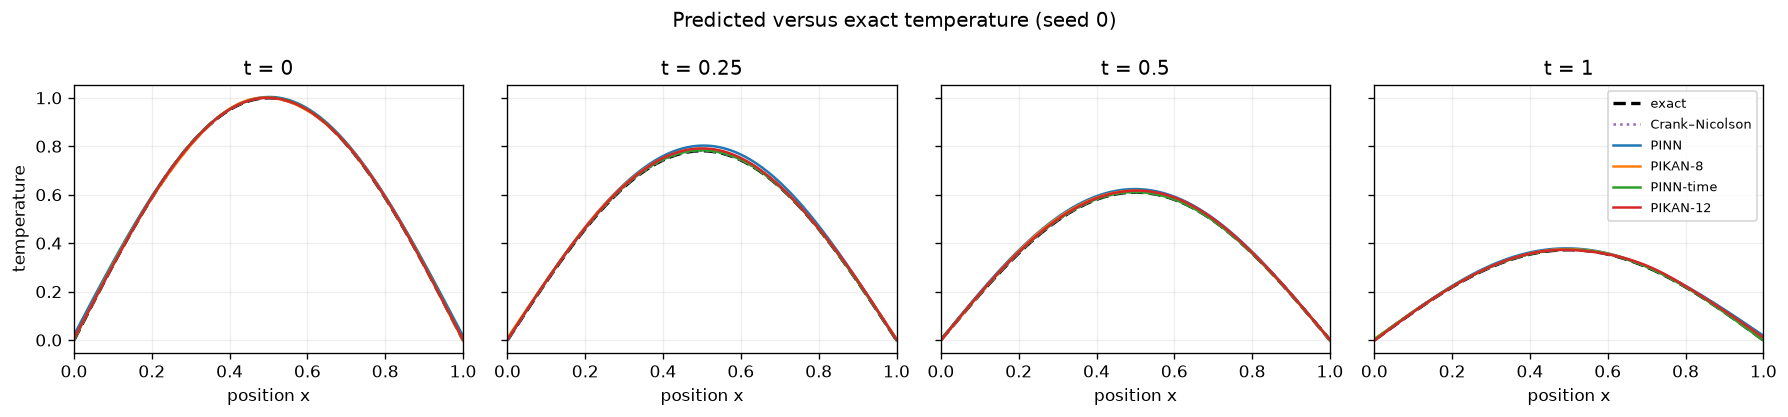

In [10]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.5), sharey=True)
xs = torch.linspace(0, 1, 201)
for ax, t in zip(axes, (0.0, 0.25, 0.5, 1.0)):
    coordinates = torch.stack((xs, torch.full_like(xs, t)), 1)
    with torch.no_grad():
        ax.plot(xs, exact_temperature(coordinates), "k--", lw=2, label="exact")
        ax.plot(cn_x, cn_field[:, int(round(t * 100))], color="#9467bd", linestyle=":", label="Crank–Nicolson")
        for name in ("PINN", "PIKAN-8", "PINN-time", "PIKAN-12"):
            ax.plot(xs, models[(name, 0)](coordinates), label=name)
    ax.set(title=f"t = {t:g}", xlabel="position x", xlim=(0, 1))
    ax.grid(True, alpha=.2)
axes[0].set_ylabel("temperature")
axes[-1].legend(fontsize=8)
fig.suptitle("Predicted versus exact temperature (seed 0)")
plt.tight_layout()
plt.show()

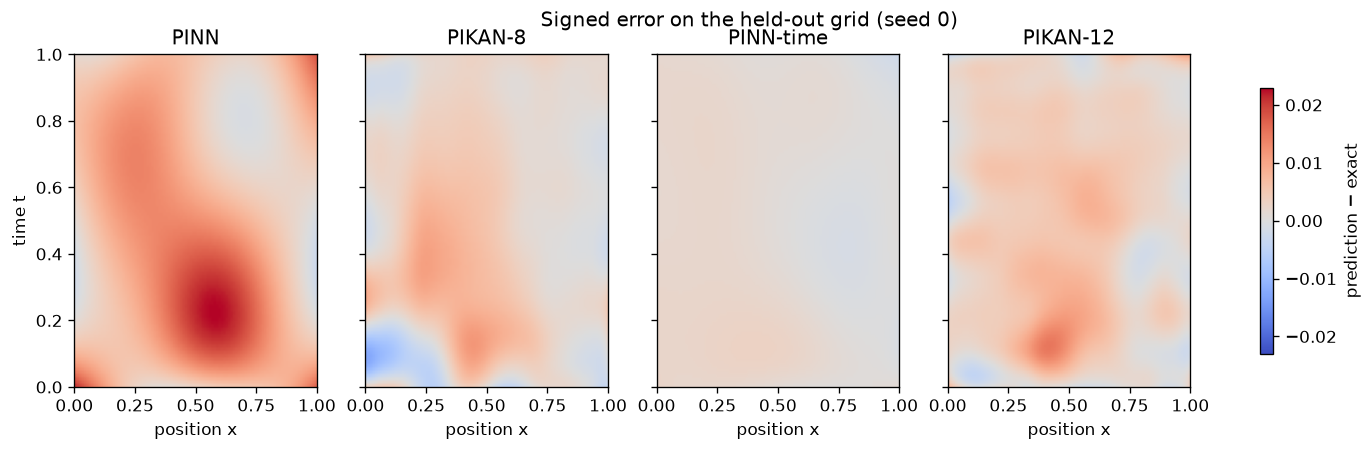

In [11]:
error_maps = []
with torch.no_grad():
    for name in ("PINN", "PIKAN-8", "PINN-time", "PIKAN-12"):
        error_maps.append((models[(name, 0)](test_coords) - truth).reshape(101, 101).numpy())
scale = max(np.abs(error).max() for error in error_maps)
fig, axes = plt.subplots(1, 4, figsize=(15, 3.6), sharex=True, sharey=True)
for ax, name, error in zip(axes, ("PINN", "PIKAN-8", "PINN-time", "PIKAN-12"), error_maps):
    image = ax.imshow(error.T, origin="lower", extent=(0, 1, 0, 1), cmap="coolwarm",
                      vmin=-scale, vmax=scale, aspect="auto")
    ax.set(title=name, xlabel="position x")
axes[0].set_ylabel("time t")
fig.colorbar(image, ax=axes, label="prediction − exact", shrink=.8)
fig.suptitle("Signed error on the held-out grid (seed 0)")
plt.show()

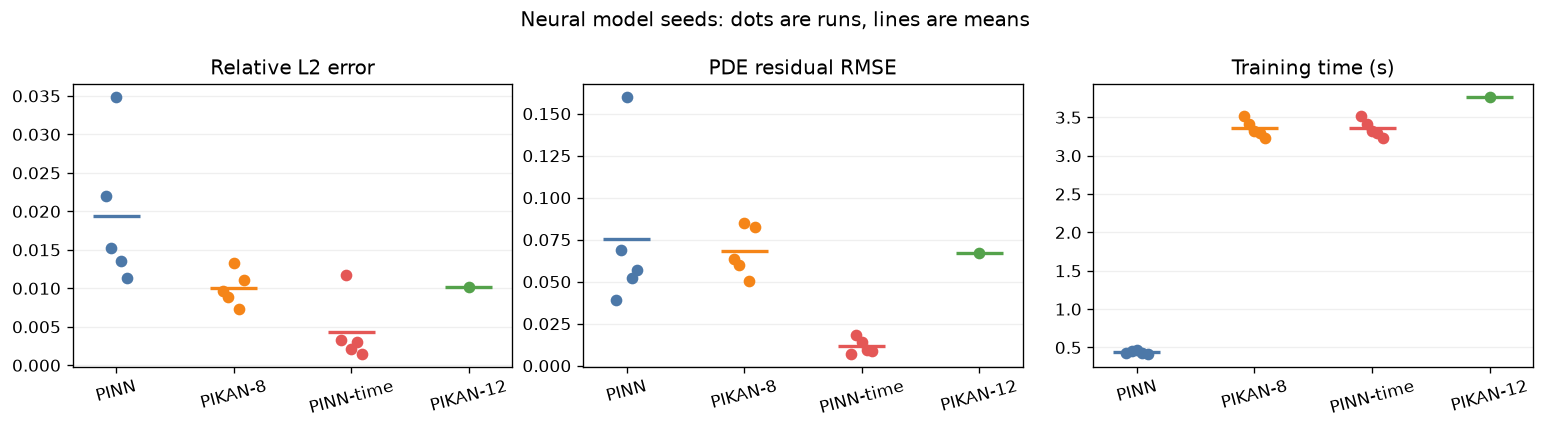

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
names = ("PINN", "PIKAN-8", "PINN-time", "PIKAN-12")
colors = ("#4c78a8", "#f58518", "#e45756", "#54a24b")
for ax, metric, title in zip(axes,
                             ("relative_L2", "PDE_residual_RMSE", "train_seconds"),
                             ("Relative L2 error", "PDE residual RMSE", "Training time (s)")):
    for pos, (name, color) in enumerate(zip(names, colors)):
        values = results.loc[results.model == name, metric].to_numpy()
        jitter = np.linspace(-.09, .09, len(values)) if len(values) > 1 else [0]
        ax.scatter(pos + np.asarray(jitter), values, color=color, zorder=3)
        ax.hlines(values.mean(), pos - .2, pos + .2, colors=color, linewidth=2)
    ax.set_xticks(range(4), names, rotation=15)
    ax.set_title(title)
    ax.grid(axis="y", alpha=.2)
fig.suptitle("Neural model seeds: dots are runs, lines are means")
plt.tight_layout()
plt.show()

## 7. Measured conclusions

The statements below are generated from the current result table. They should be read as findings for this budget and these seeds, rather than a general ranking of architectures.

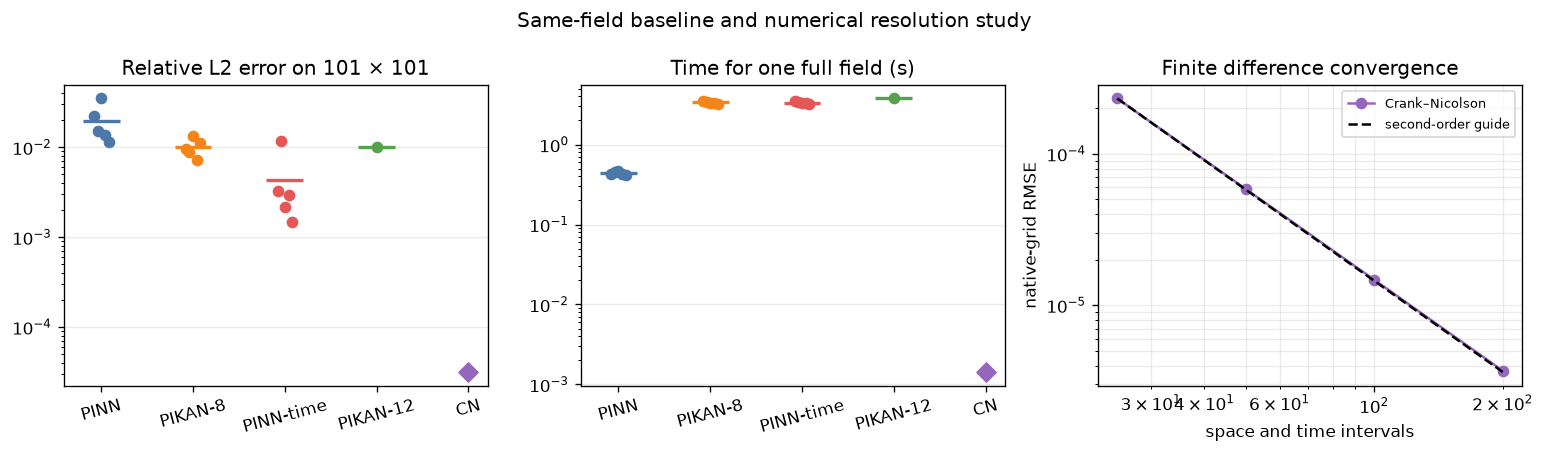

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, metric, title in zip(axes[:2], ("relative_L2", "one_field_seconds"),
                             ("Relative L2 error on 101 × 101", "Time for one full field (s)")):
    for pos, (name, color) in enumerate(zip(names, colors)):
        values = results.loc[results.model == name, metric].to_numpy()
        jitter = np.linspace(-.08, .08, len(values)) if len(values) > 1 else [0]
        ax.scatter(pos + np.asarray(jitter), values, color=color)
        ax.hlines(values.mean(), pos - .2, pos + .2, colors=color, linewidth=2)
    ax.scatter([4], [cn_relative_l2 if metric == "relative_L2" else cn_full_seconds],
               marker="D", s=65, color="#9467bd")
    ax.set_xticks(range(5), [*names, "CN"], rotation=15)
    ax.set_yscale("log")
    ax.set_title(title)
    ax.grid(axis="y", alpha=.25)
axes[2].loglog(resolution_df.intervals, resolution_df.RMSE, "o-", color="#9467bd", label="Crank–Nicolson")
axes[2].loglog(resolution_df.intervals,
               resolution_df.RMSE.iloc[0] * (resolution_df.intervals.iloc[0] / resolution_df.intervals)**2,
               "k--", label="second-order guide")
axes[2].set(xlabel="space and time intervals", ylabel="native-grid RMSE", title="Finite difference convergence")
axes[2].legend(fontsize=8)
axes[2].grid(True, which="both", alpha=.25)
fig.suptitle("Same-field baseline and numerical resolution study")
plt.tight_layout()
plt.show()

In [14]:
summary = results.groupby("model").agg(
    runs=("seed", "size"), parameters=("parameters", "first"),
    relative_L2_mean=("relative_L2", "mean"), relative_L2_std=("relative_L2", "std"),
    residual_mean=("PDE_residual_RMSE", "mean"),
    train_seconds_mean=("train_seconds", "mean"),
    inference_ms_mean=("inference_ms_per_1024", "mean"),
    one_field_seconds_mean=("one_field_seconds", "mean")
)
display(summary)

pinn = summary.loc["PINN"]
kan = summary.loc["PIKAN-8"]
time_pinn = summary.loc["PINN-time"]
grid12 = summary.loc["PIKAN-12"]
winner = "PIKAN-8" if kan.relative_L2_mean < pinn.relative_L2_mean else "PINN"
error_ratio = kan.relative_L2_mean / pinn.relative_L2_mean
time_ratio = kan.train_seconds_mean / pinn.train_seconds_mean
param_ratio = kan.parameters / pinn.parameters
print(f"• Across {len(SEEDS)} matched seeds, {winner} had the lower mean relative L2 error. "
      f"PIKAN-8 / PINN error ratio: {error_ratio:.2f}×.")
print(f"• PIKAN-8 used {kan.parameters:.0f} parameters versus {pinn.parameters:.0f} for PINN "
      f"({param_ratio:.2f}×), and took {time_ratio:.2f}× as long to train per run.")
equal_time_winner = "PIKAN-8" if kan.relative_L2_mean < time_pinn.relative_L2_mean else "PINN-time"
print(f"• With approximately equal CPU training time, {equal_time_winner} had the lower mean "
      f"relative L2: PINN-time {time_pinn.relative_L2_mean:.3g} versus PIKAN-8 "
      f"{kan.relative_L2_mean:.3g}. PINN-time update counts vary slightly by seed.")
print(f"• Mean held-out PDE residual RMSE was {pinn.residual_mean:.3g} for PINN and "
      f"{kan.residual_mean:.3g} for PIKAN-8. Lower temperature error and lower residual need not coincide.")
print(f"• With seed {SEEDS[0]}, changing KAN centers from 8 to 12 changed relative L2 from "
      f"{results[(results.model == 'PIKAN-8') & (results.seed == SEEDS[0])].relative_L2.iloc[0]:.3g} "
      f"to {grid12.relative_L2_mean:.3g}; parameter count changed from {kan.parameters:.0f} "
      f"to {grid12.parameters:.0f}. This single-seed grid check is exploratory.")
best_neural = min(pinn.relative_L2_mean, kan.relative_L2_mean, time_pinn.relative_L2_mean)
best_neural_time = min(pinn.one_field_seconds_mean, kan.one_field_seconds_mean, time_pinn.one_field_seconds_mean)
order = np.polyfit(np.log(resolution_df.dx), np.log(resolution_df.RMSE), 1)[0]
print(f"• Crank–Nicolson at 100×100 intervals reached relative L2 {cn_relative_l2:.3g} "
      f"and produced the full 101×101 field in {cn_full_seconds * 1000:.3g} ms. "
      f"The best five-seed neural mean error was {best_neural / cn_relative_l2:.1f}× larger; "
      f"even the faster neural mean one-field time was {best_neural_time / cn_full_seconds:.0f}× longer.")
print(f"• Crank–Nicolson's native-grid RMSE fell with an observed log-log slope of {order:.2f} "
      "as dx=dt shrank, consistent with second-order convergence for this smooth case.")
plain_pinn_grid_ms = results.loc[results.model == "PINN", "full_grid_inference_ms"].mean()
kan_grid_ms = results.loc[results.model == "PIKAN-8", "full_grid_inference_ms"].mean()
print(f"• After training, full-grid PINN inference averaged {plain_pinn_grid_ms:.3g} ms "
      f"and PIKAN-8 inference averaged {kan_grid_ms:.3g} ms, versus "
      f"{1000 * cn_full_seconds:.3g} ms for a fresh numerical solve and "
      f"{cn_cached_field_ms:.3g} ms to copy its cached field.")
if plain_pinn_grid_ms < 1000 * cn_full_seconds:
    repeated_fields = math.ceil(1000 * pinn.train_seconds_mean / (1000 * cn_full_seconds - plain_pinn_grid_ms))
    print(f"• If the identical PDE were unnecessarily re-solved for every full-field request, "
          f"the 400-step PINN would recover training cost after roughly {repeated_fields:,} requests. "
          "Caching the numerical field is faster for this fixed problem.")
else:
    print("• Even without numerical caching, full-grid PINN inference did not beat a fresh solve here.")
print(f"• For 1024 arbitrary coordinates, cached numerical interpolation took {cn_query_ms:.3g} ms "
      f"at relative L2 error {cn_query_error:.3g}; the notebook's query table reports the neural "
      "latency and error on the same coordinates.")
print(f"• Because the exact formula is known for this particular setup, evaluating it took "
      f"{exact_grid_ms:.3g} ms for the full field and {exact_query_ms:.3g} ms for 1024 coordinates. "
      "This is a direct reference calculation, not a learned or numerical approximation.")
print("• Scope: five matched neural seeds, one optimizer and loss-weight choice, one fixed collocation set per seed, "
      "and CPU-only timing. The current models take only (x,t), so they cannot reuse weights for a new "
      "diffusivity, initial condition, or boundary condition. A parametric surrogate would need those "
      "inputs during training and a separate benchmark across many PDE instances.")

• Across 5 matched seeds, PIKAN-8 had the lower mean relative L2 error. PIKAN-8 / PINN error ratio: 0.52×.
• PIKAN-8 used 499 parameters versus 501 for PINN (1.00×), and took 7.65× as long to train per run.
• With approximately equal CPU training time, PINN-time had the lower mean relative L2: PINN-time 0.00431 versus PIKAN-8 0.01. PINN-time update counts vary slightly by seed.
• Mean held-out PDE residual RMSE was 0.0755 for PINN and 0.0684 for PIKAN-8. Lower temperature error and lower residual need not coincide.
• With seed 0, changing KAN centers from 8 to 12 changed relative L2 from 0.00967 to 0.0101; parameter count changed from 499 to 715. This single-seed grid check is exploratory.
• Crank–Nicolson at 100×100 intervals reached relative L2 3.17e-05 and produced the full 101×101 field in 1.43 ms. The best five-seed neural mean error was 136.1× larger; even the faster neural mean one-field time was 307× longer.
• Crank–Nicolson's native-grid RMSE fell with an observed log-log slop

,runs,parameters,relative_L2_mean,relative_L2_std,residual_mean,train_seconds_mean,inference_ms_mean,one_field_seconds_mean
model,,,,,,,,
PIKAN-12,1,715,0.010143,NaN,0.067041,3.762354,0.612375,3.769512
PIKAN-8,5,499,0.010034,0.002267,0.068391,3.355472,0.597084,3.360911
PINN,5,501,0.019404,0.009502,0.075517,0.438446,0.082120,0.438716
PINN-time,5,501,0.004315,0.004180,0.011507,3.356300,0.081628,3.356544


## 8. What this experiment can establish

- **Sound as a learning exercise:** The networks and numerical solver satisfy independent derivative, boundary, exact-residual, and grid-convergence checks. The exact solution is withheld from interior training.
- **Narrow as a research claim:** One smooth sine mode with a known formula is too simple to demonstrate that a neural surrogate is useful in practice. The result concerns these architectures and settings, not all PINNs or KANs. The spline model also uses hidden tanh and fixed knots, so it is a KAN-style variant. One nearly matched parameter count does not establish parameter efficiency; that requires an accuracy-versus-size sweep.
- **Data-driven direction:** Adding dense labels from the exact formula for the same fixed problem would mainly teach a network to imitate an already cheap function. A useful next phase is a *family* of heat problems with varying spatial diffusivity, sources, or initial profiles. Generate reference fields numerically; train supervised, physics-informed, and hybrid models; hold out entire problem instances; then compare accuracy and total cost for many queries at a matched error target.
- **Alternative if measurements matter:** Use sparse, possibly noisy temperature observations to infer an unknown diffusivity or source term. Then data and physics each supply information the other lacks.

### References

- Raissi, Perdikaris & Karniadakis (2019), *Physics-informed neural networks*, Journal of Computational Physics, DOI: 10.1016/j.jcp.2018.10.045.
- Liu et al. (2024), *KAN: Kolmogorov–Arnold Networks*, arXiv:2404.19756.
- Patra et al. (2025), *Physics Informed Kolmogorov-Arnold Neural Networks for Dynamical Analysis via Efficient-KAN and WAV-KAN*, JMLR 26(233).
- SciPy documentation, [`splu`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.sparse.linalg.splu.html), sparse LU factorization used by the finite difference baseline.
- Li et al. (2021), [*Fourier Neural Operator for Parametric Partial Differential Equations*](https://arxiv.org/abs/2010.08895), an example of learning across PDE inputs rather than fitting one fixed instance.